# Task 1 — Text-to-Image Generation with Stable Diffusion (LoRA fine-tuning)

**Assignment 6 · Image Generation by Stable Diffusion.** This notebook implements
**Task 1** end-to-end and produces every artefact the final report asks for.

| Report section | Where it is produced |
|---|---|
| §2 Stable Diffusion architecture | §2 below — component + parameter table |
| §3 Dataset description | §3–§4 — image–text pairs, splits, preprocessing |
| §4–§5 Methodology / fine-tuning | §5–§6 — LoRA setup + training loop |
| §7 Results (≥10 generated images) | §7 |
| §8 Quantitative evaluation | §9 — **CLIP similarity, FID, SSIM** |
| §9 Qualitative evaluation | §8, §11 — target-vs-generated grids |
| §10 Parameter analysis | §10 — steps / guidance / resolution / seed / prompt |
| §12 Discussion | §11 prompt-complexity study + §12 |

### The "Important Question": what are `x` and `y` for text-to-image?

During fine-tuning the model learns $p(y \mid x)$ where

- **`x` (condition) = the text prompt only**, encoded by CLIP into 77 token embeddings;
- **`y` (target) = the image**, encoded by the VAE into a latent that is noised and then
  denoised by the UNet.

There is **no image on the input side** — the only conditioning signal is text. That is the
distinction from the other three tasks: image-to-image, inpainting, and outpainting all add
an *image latent* (and, for the mask-based tasks, a mask) to the UNet input, so their `x`
carries pixels as well as text. Text-to-image is the one task conditioned on text alone.

## 0. Environment

Install the libraries. On Windows we deliberately avoid `xformers`/`bitsandbytes`
(fragile there) — LoRA fine-tuning of SD-1.5 fits comfortably on a single 16 GB GPU without
them. Skip this cell if the packages are already present.

In [1]:
%pip install -q "diffusers>=0.27" "transformers>=4.38" accelerate peft datasets safetensors ftfy "torchmetrics[image]" scipy matplotlib pandas pillow tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports, configuration, and reproducibility

Everything tunable lives in the `CFG` block, so re-running the study at a different budget
means editing one place. `QUICK_MODE` gives a fast smoke-test (fewer steps / fewer images);
turn it off for the full run reported in the paper.

In [2]:
import os, gc, json, time, math, random
from pathlib import Path
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torchvision import transforms

torch.backends.cuda.matmul.allow_tf32 = True

@dataclass
class CFG:
    # --- model ---
    model_id: str = "stable-diffusion-v1-5/stable-diffusion-v1-5"  # community mirror of SD-1.5
    resolution: int = 512

    # --- dataset ---
    # Default: a small PUBLIC captioned demo set that makes the fine-tuning effect obvious.
    # We try several ungated mirrors in order (some HF caption sets are gated and need a
    # token). To use the CLASS COMMON dataset instead, set use_local_dataset=True and point
    # local_data_dir at a folder holding images + a metadata.csv/.jsonl with an image column
    # and a text/caption column (HF "imagefolder" layout).
    hf_dataset_candidates: tuple = (
        "reach-vb/pokemon-blip-captions",     # public mirror of the classic BLIP set, cols [image, text]
        "diffusers/pokemon-gpt4-captions",    # GPT-4 captions, cols [image, text]
        "svjack/pokemon-blip-captions-en-zh", # cols [image, en_text, zh_text]
        "Norod78/simpsons-blip-captions",
    )
    use_local_dataset: bool = False
    local_data_dir: str = "data/class_dataset"
    max_train_samples: int | None = None      # None = use all
    val_fraction: float = 0.1

    # --- LoRA fine-tuning ---
    lora_rank: int = 8
    lora_alpha: int = 8
    learning_rate: float = 1e-4
    train_batch_size: int = 1
    grad_accum: int = 4                        # effective batch = 4
    max_train_steps: int = 800
    lr_warmup_steps: int = 50
    seed: int = 42

    # --- generation defaults ---
    num_inference_steps: int = 30
    guidance_scale: float = 7.5

    # --- evaluation ---
    n_fid_images: int = 32                     # real/fake set size for FID (small — see caveat)

    quick_mode: bool = True

CFG = CFG()
if CFG.quick_mode:
    CFG.max_train_steps = 200
    CFG.n_fid_images = 12

# reproducibility
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

# device + precision (bf16 on Ampere/Blackwell, else fp16 + GradScaler, else fp32)
device = "cuda" if torch.cuda.is_available() else "cpu"
use_cuda = device == "cuda"
if use_cuda and torch.cuda.is_bf16_supported():
    weight_dtype, amp_dtype, use_scaler = torch.bfloat16, torch.bfloat16, False
elif use_cuda:
    weight_dtype, amp_dtype, use_scaler = torch.float16, torch.float16, True
else:
    weight_dtype, amp_dtype, use_scaler = torch.float32, torch.float32, False

# output folders (mirrors the layout used in the other assignments)
OUT = Path("outputs")
FIG, RES_DIR, GEN, LORA_DIR = OUT/"figures", OUT/"results", OUT/"generated", OUT/"lora"
for d in (FIG, RES_DIR, GEN, LORA_DIR): d.mkdir(parents=True, exist_ok=True)

print(f"device={device}  gpu={torch.cuda.get_device_name(0) if use_cuda else 'cpu'}")
print(f"weight_dtype={weight_dtype}  grad_scaler={use_scaler}")
print("config:", json.dumps(asdict(CFG), indent=2))

device=cuda  gpu=NVIDIA GeForce RTX 5070 Ti
weight_dtype=torch.bfloat16  grad_scaler=False
config: {
  "model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "resolution": 512,
  "hf_dataset_candidates": [
    "reach-vb/pokemon-blip-captions",
    "diffusers/pokemon-gpt4-captions",
    "svjack/pokemon-blip-captions-en-zh",
    "Norod78/simpsons-blip-captions"
  ],
  "use_local_dataset": false,
  "local_data_dir": "data/class_dataset",
  "max_train_samples": null,
  "val_fraction": 0.1,
  "lora_rank": 8,
  "lora_alpha": 8,
  "learning_rate": 0.0001,
  "train_batch_size": 1,
  "grad_accum": 4,
  "max_train_steps": 200,
  "lr_warmup_steps": 50,
  "seed": 42,
  "num_inference_steps": 30,
  "guidance_scale": 7.5,
  "n_fid_images": 12,
  "quick_mode": true
}


## 2. Stable Diffusion architecture (report §2)

Stable Diffusion is a **latent** diffusion model: diffusion happens in the VAE's 64×64×4
latent space, not in 512×512 pixel space, which is what makes it tractable. Three learned
components plus one scheduler:

- **Text encoder** — CLIP ViT-L/14, turns the prompt into 77 conditioning token embeddings.
- **VAE** — encodes an image to a latent (8× spatial downsample) and decodes it back.
- **UNet** — the denoiser; predicts the noise added to the latent, conditioned on the text
  embeddings via cross-attention.
- **Noise scheduler** — defines the forward/reverse noising process (DDPM, scaled-linear β).

We load the four components separately (rather than the packaged pipeline) because the
training loop needs direct access to each. The cell prints the exact parameter counts for
the report table.

In [3]:
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler

tokenizer     = CLIPTokenizer.from_pretrained(CFG.model_id, subfolder="tokenizer")
text_encoder  = CLIPTextModel.from_pretrained(CFG.model_id, subfolder="text_encoder")
vae           = AutoencoderKL.from_pretrained(CFG.model_id, subfolder="vae")
unet          = UNet2DConditionModel.from_pretrained(CFG.model_id, subfolder="unet")
noise_scheduler = DDPMScheduler.from_pretrained(CFG.model_id, subfolder="scheduler")

def count_params(m): return sum(p.numel() for p in m.parameters())
arch = pd.DataFrame([
    {"Component": "Text encoder (CLIP ViT-L/14)", "Params (M)": round(count_params(text_encoder)/1e6, 2)},
    {"Component": "VAE (AutoencoderKL)",          "Params (M)": round(count_params(vae)/1e6, 2)},
    {"Component": "UNet (denoiser)",              "Params (M)": round(count_params(unet)/1e6, 2)},
])
arch.loc[len(arch)] = ["TOTAL", round(arch["Params (M)"].sum(), 2)]
arch.to_csv(RES_DIR/"architecture.csv", index=False)

print(f"model              : {CFG.model_id}")
print(f"resolution         : {CFG.resolution}x{CFG.resolution}")
print(f"latent shape       : 4 x {CFG.resolution//8} x {CFG.resolution//8}  (VAE scale factor {vae.config.scaling_factor})")
print(f"prediction type    : {noise_scheduler.config.prediction_type}")
print(f"train timesteps    : {noise_scheduler.config.num_train_timesteps}")
print(f"beta schedule      : {noise_scheduler.config.beta_schedule}")
arch

model              : stable-diffusion-v1-5/stable-diffusion-v1-5
resolution         : 512x512
latent shape       : 4 x 64 x 64  (VAE scale factor 0.18215)
prediction type    : epsilon
train timesteps    : 1000
beta schedule      : scaled_linear


,Component,Params (M)
0,Text encoder (CLIP ViT-L/14),123.06
1,VAE (AutoencoderKL),83.65
2,UNet (denoiser),859.52
3,TOTAL,1066.23


## 3. Dataset — image–text pairs (report §3)

The assignment requires the **class common dataset**. Point the loader at it by setting
`CFG.use_local_dataset = True` and `CFG.local_data_dir` to a folder in HuggingFace
*imagefolder* layout (images + a `metadata.csv`/`metadata.jsonl` with an image column and a
caption column). Until that dataset is ready, the notebook falls back to a small public
captioned set (`pokemon-blip-captions`, ~833 pairs) so the whole pipeline runs and the
fine-tuning effect is clearly visible.

> **`x`/`y` here:** each training example is `(caption → image)`. The caption is `x`, the
> image is `y`. No image enters on the conditioning side — that is unique to text-to-image.

In [4]:
from datasets import load_dataset
from datasets.features import Image as HFImage, Value

ds_all = None
if CFG.use_local_dataset and Path(CFG.local_data_dir).exists():
    ds_all = load_dataset("imagefolder", data_dir=CFG.local_data_dir, split="train")
    print(f"Loaded LOCAL dataset from {CFG.local_data_dir}")
else:
    if CFG.use_local_dataset:
        print(f"[warn] local_data_dir '{CFG.local_data_dir}' not found — falling back to HF.")
    # try the public candidates in order; keep the first that loads
    for name in CFG.hf_dataset_candidates:
        try:
            ds_all = load_dataset(name, split="train")
            print(f"Loaded HF dataset: {name}")
            break
        except Exception as e:
            print(f"[skip] {name}: {type(e).__name__}: {str(e).splitlines()[0][:80]}")
    assert ds_all is not None, ("No candidate dataset could be loaded. Set "
        "CFG.use_local_dataset=True and provide CFG.local_data_dir, or `huggingface-cli login`.")

# normalise columns -> 'image' and 'text' (detect by feature type, robust to naming)
feats = ds_all.features
img_col  = next((c for c, f in feats.items() if isinstance(f, HFImage)), None)
text_cands = [c for c in ["text","caption","captions","prompt","en_text","english_text",
                          "sentence","description"] if c in feats]
text_col = text_cands[0] if text_cands else next(
    (c for c, f in feats.items() if isinstance(f, Value) and f.dtype == "string"), None)
assert img_col and text_col, f"could not find image/caption columns in {list(feats)}"
keep = [img_col, text_col]
ds_all = ds_all.remove_columns([c for c in ds_all.column_names if c not in keep])
if text_col != "text": ds_all = ds_all.rename_column(text_col, "text")
if img_col  != "image": ds_all = ds_all.rename_column(img_col, "image")

if CFG.max_train_samples:
    ds_all = ds_all.select(range(min(CFG.max_train_samples, len(ds_all))))

split = ds_all.train_test_split(test_size=CFG.val_fraction, seed=CFG.seed)
train_ds, val_ds = split["train"], split["test"]
print(f"total={len(ds_all)}  train={len(train_ds)}  val={len(val_ds)}")
print("example caption:", train_ds[0]["text"])

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


(…)-00000-of-00001-566cc9b19d7203f8.parquet:   0%|          | 0.00/99.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/833 [00:00<?, ? examples/s]

Loaded HF dataset: reach-vb/pokemon-blip-captions
total=833  train=749  val=84
example caption: a yellow and black cartoon character with a big smile


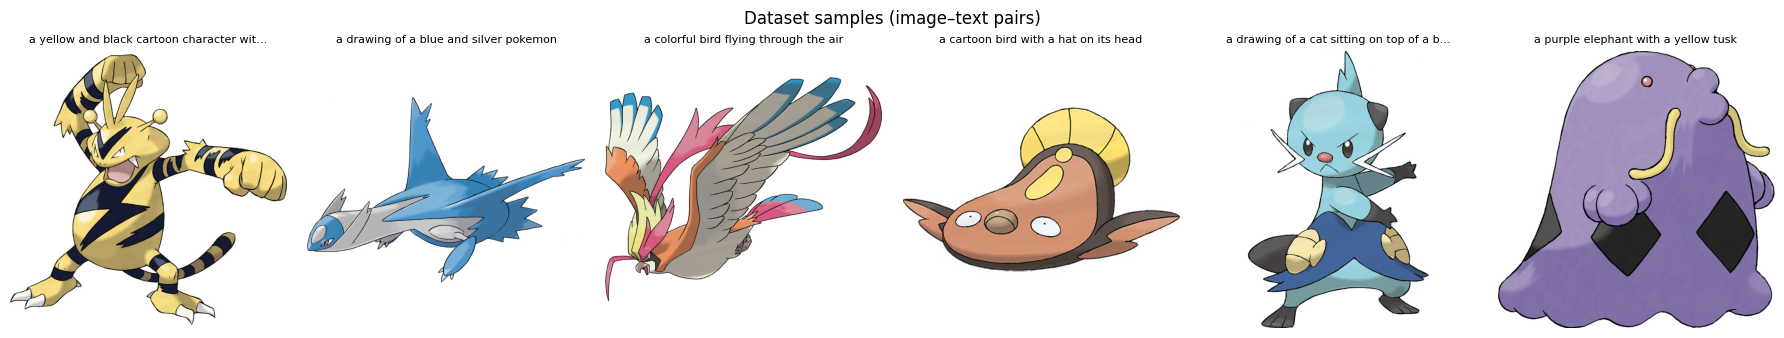

In [5]:
# visualise a few image-text pairs
def show_pairs(dataset, n=6, fname=None, title="Dataset samples (image–text pairs)"):
    n = min(n, len(dataset))
    fig, axes = plt.subplots(1, n, figsize=(3*n, 3.4))
    if n == 1: axes = [axes]
    for i, ax in enumerate(axes):
        ex = dataset[i]
        ax.imshow(ex["image"]); ax.axis("off")
        cap = ex["text"]
        ax.set_title((cap[:40] + "…") if len(cap) > 40 else cap, fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    if fname: fig.savefig(FIG/fname, dpi=130, bbox_inches="tight")
    plt.show()

show_pairs(train_ds, n=6, fname="t1_dataset_samples.png")

## 4. Preprocessing and tokenization (report §3)

Images are resized so the short side is `resolution`, centre-cropped to a square, randomly
horizontally flipped (light augmentation), and normalised to $[-1, 1]$ — the range the VAE
expects. Captions are tokenized to a fixed length of 77 with CLIP's tokenizer. On Windows we
use `num_workers=0` to avoid the notebook-dataset spawn problem.

In [6]:
train_tf = transforms.Compose([
    transforms.Resize(CFG.resolution, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.CenterCrop(CFG.resolution),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),       # -> [-1, 1]
])

def tokenize(caption):
    return tokenizer(caption, max_length=tokenizer.model_max_length,
                     padding="max_length", truncation=True, return_tensors="pt").input_ids[0]

class PairDataset(torch.utils.data.Dataset):
    def __init__(self, hf_ds): self.ds = hf_ds
    def __len__(self): return len(self.ds)
    def __getitem__(self, i):
        ex = self.ds[i]
        img = ex["image"].convert("RGB")
        return {"pixel_values": train_tf(img), "input_ids": tokenize(ex["text"])}

def collate(batch):
    return {
        "pixel_values": torch.stack([b["pixel_values"] for b in batch]),
        "input_ids":    torch.stack([b["input_ids"]    for b in batch]),
    }

train_loader = torch.utils.data.DataLoader(
    PairDataset(train_ds), batch_size=CFG.train_batch_size, shuffle=True,
    collate_fn=collate, num_workers=0, drop_last=True)
print(f"batches/epoch = {len(train_loader)}  (effective batch {CFG.train_batch_size*CFG.grad_accum})")

batches/epoch = 749  (effective batch 4)


## 5. Fine-tuning setup — LoRA on the UNet (report §5)

**What is trained vs. frozen.** Full fine-tuning of SD-1.5 means training all ~860 M UNet
parameters — expensive and prone to catastrophic forgetting on a small dataset. Instead we
use **LoRA**: the VAE and text encoder are *frozen*, the UNet's original weights are
*frozen*, and we insert small low-rank adapter matrices into the UNet's attention
projections (`to_q, to_k, to_v, to_out`). Only those adapters train — typically well under
1% of the parameters — which fits on one GPU and keeps the base model's general knowledge
intact.

Frozen models are moved to the GPU in low precision; the trainable LoRA parameters are kept
in fp32 for numerically stable optimisation. The VAE is deliberately kept in **fp32** because
SD's VAE can emit NaNs in fp16.

In [7]:
from peft import LoraConfig
try:
    from diffusers.training_utils import cast_training_params
except Exception:
    def cast_training_params(model, dtype=torch.float32):
        for p in model.parameters():
            if p.requires_grad: p.data = p.data.to(dtype)
from diffusers.optimization import get_scheduler

# freeze everything
vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(False)

# place on device: VAE in fp32 (stability), text-encoder + UNet base in weight_dtype
vae.to(device, dtype=torch.float32)
text_encoder.to(device, dtype=weight_dtype)
unet.to(device, dtype=weight_dtype)

# inject LoRA adapters into the UNet attention blocks
lora_config = LoraConfig(
    r=CFG.lora_rank, lora_alpha=CFG.lora_alpha, init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"])
unet.add_adapter(lora_config)
cast_training_params(unet, dtype=torch.float32)   # LoRA params -> fp32

lora_params = [p for p in unet.parameters() if p.requires_grad]
n_train = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"trainable LoRA params : {n_train:,}  ({100*n_train/n_total:.3f}% of the UNet)")

optimizer = torch.optim.AdamW(lora_params, lr=CFG.learning_rate)
lr_scheduler = get_scheduler("cosine", optimizer=optimizer,
                             num_warmup_steps=CFG.lr_warmup_steps,
                             num_training_steps=CFG.max_train_steps)

trainable LoRA params : 1,594,368  (0.185% of the UNet)


## 6. Training loop (report §5)

The standard latent-diffusion objective. For each batch:

1. encode the image to a latent with the (frozen) VAE and scale it;
2. sample Gaussian noise and a random timestep `t`;
3. add `t` steps of noise to the latent (the forward process);
4. ask the UNet to predict that noise from the noisy latent + text embedding;
5. minimise MSE between predicted and true noise (ε-prediction).

Only the LoRA adapters receive gradients. Mixed precision uses bf16 (no loss scaler) or
fp16 (with a `GradScaler`) automatically. The loss curve is saved for report §5.

In [8]:
scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
loss_hist, step_hist = [], []
global_step = 0
unet.train()
set_seed(CFG.seed)

t0 = time.time()
pbar = tqdm(total=CFG.max_train_steps, desc="training")
optimizer.zero_grad(set_to_none=True)
done = False
while not done:
    for batch in train_loader:
        pixel_values = batch["pixel_values"].to(device, dtype=torch.float32)   # VAE is fp32
        input_ids    = batch["input_ids"].to(device)

        with torch.no_grad():
            latents = vae.encode(pixel_values).latent_dist.sample() * vae.config.scaling_factor
            latents = latents.to(weight_dtype)
            enc_hidden = text_encoder(input_ids)[0]

        noise = torch.randn_like(latents)
        bsz = latents.shape[0]
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                                  (bsz,), device=device).long()
        noisy = noise_scheduler.add_noise(latents, noise, timesteps)

        if noise_scheduler.config.prediction_type == "v_prediction":
            target = noise_scheduler.get_velocity(latents, noise, timesteps)
        else:
            target = noise

        with torch.autocast("cuda", dtype=amp_dtype, enabled=use_cuda):
            model_pred = unet(noisy, timesteps, enc_hidden).sample
            loss = F.mse_loss(model_pred.float(), target.float()) / CFG.grad_accum

        if use_scaler: scaler.scale(loss).backward()
        else:          loss.backward()

        if (global_step + 1) % CFG.grad_accum == 0:
            if use_scaler:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(lora_params, 1.0)
                scaler.step(optimizer); scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(lora_params, 1.0)
                optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            lr_scheduler.step()

        loss_hist.append(loss.item() * CFG.grad_accum); step_hist.append(global_step)
        global_step += 1; pbar.update(1)
        pbar.set_postfix(loss=f"{loss_hist[-1]:.4f}", lr=f"{lr_scheduler.get_last_lr()[0]:.2e}")
        if global_step >= CFG.max_train_steps: done = True; break
pbar.close()
train_time_s = time.time() - t0
print(f"training done: {global_step} steps in {train_time_s/60:.1f} min")

training:   0%|          | 0/200 [00:00<?, ?it/s]

training done: 200 steps in 0.6 min


saved LoRA -> outputs\lora


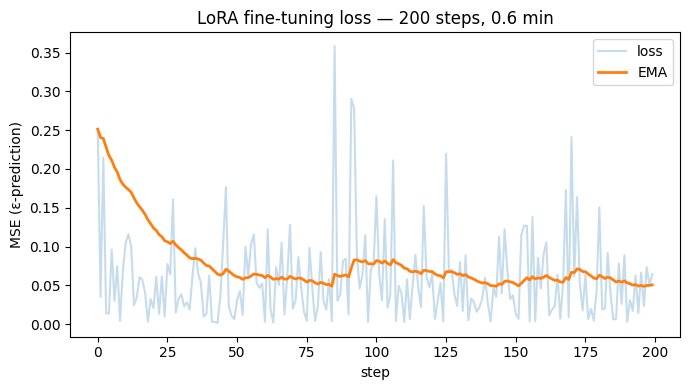

In [9]:
# save LoRA weights + training curve
from diffusers import StableDiffusionPipeline
from diffusers.utils import convert_state_dict_to_diffusers
from peft.utils import get_peft_model_state_dict

unet_lora_state = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
StableDiffusionPipeline.save_lora_weights(save_directory=str(LORA_DIR),
                                          unet_lora_layers=unet_lora_state,
                                          safe_serialization=True)
print("saved LoRA ->", LORA_DIR)

def ema(x, a=0.05):
    out, m = [], x[0]
    for v in x: m = a*v + (1-a)*m; out.append(m)
    return out

plt.figure(figsize=(7,4))
plt.plot(step_hist, loss_hist, alpha=0.25, label="loss")
plt.plot(step_hist, ema(loss_hist), lw=2, label="EMA")
plt.xlabel("step"); plt.ylabel("MSE (ε-prediction)")
plt.title(f"LoRA fine-tuning loss — {global_step} steps, {train_time_s/60:.1f} min")
plt.legend(); plt.tight_layout(); plt.savefig(FIG/"t1_training_loss.png", dpi=130); plt.show()

# free training memory before inference
del optimizer, lr_scheduler
gc.collect(); torch.cuda.empty_cache() if use_cuda else None

## 7. Generate images from prompts (report §7)

We reload a clean inference pipeline (fast, weights are cached) with a fast DPM-Solver
scheduler. We generate with the **base** model first, then load our fine-tuned LoRA and
generate again — so every prompt has a base-vs-fine-tuned pair.

The prompt set (≥10, as required) has two parts:

- **paired prompts** — captions drawn from the validation split, so each has a *real target
  image* for SSIM / CLIP-image / FID;
- **free prompts** — novel prompts of increasing complexity for the prompt-complexity study.

In [10]:
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler

pipe = StableDiffusionPipeline.from_pretrained(
    CFG.model_id, torch_dtype=weight_dtype, safety_checker=None, requires_safety_checker=False)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
pipe = pipe.to(device)

def generate(prompt, steps=None, guidance=None, res=None, seed=0, negative_prompt=None):
    g = torch.Generator(device=device).manual_seed(seed)
    res = res or CFG.resolution
    out = pipe(prompt,
               num_inference_steps=steps or CFG.num_inference_steps,
               guidance_scale=guidance if guidance is not None else CFG.guidance_scale,
               height=res, width=res, negative_prompt=negative_prompt, generator=g)
    return out.images[0]

def grid(images, titles=None, ncols=4, figsize_scale=3.0, suptitle=None, fname=None):
    n = len(images); ncols = min(ncols, n); nrows = math.ceil(n/ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_scale*ncols, figsize_scale*nrows))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(images[i]); ax.axis("off")
            if titles: ax.set_title(titles[i], fontsize=8)
        else: ax.axis("off")
    if suptitle: fig.suptitle(suptitle)
    fig.tight_layout()
    if fname: fig.savefig(FIG/fname, dpi=130, bbox_inches="tight")
    plt.show()

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

In [11]:
# paired prompts (real target images) from the validation split
n_paired = 6 if not CFG.quick_mode else 4
paired = []
for i in range(min(n_paired, len(val_ds))):
    ex = val_ds[i]
    paired.append({"prompt": ex["text"],
                   "target": ex["image"].convert("RGB").resize((CFG.resolution, CFG.resolution))})

# free prompts of increasing complexity
free_prompts = [
    "a red apple",                                                        # simple
    "a golden retriever puppy",                                           # simple
    "a red sports car parked beside a lake at sunset",                    # medium
    "a cup of coffee on a wooden table next to a rainy window",           # medium
    "a cozy bookstore cafe interior, warm lighting, plants, morning sun", # complex
    "an astronaut riding a horse on the moon, earth in the sky, cinematic lighting, highly detailed",  # complex
]
all_prompts = [p["prompt"] for p in paired] + free_prompts
print(f"{len(all_prompts)} prompts total ({len(paired)} paired + {len(free_prompts)} free)")

10 prompts total (4 paired + 6 free)


base:   0%|          | 0/10 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


fine-tuned:   0%|          | 0/10 [00:00<?, ?it/s]

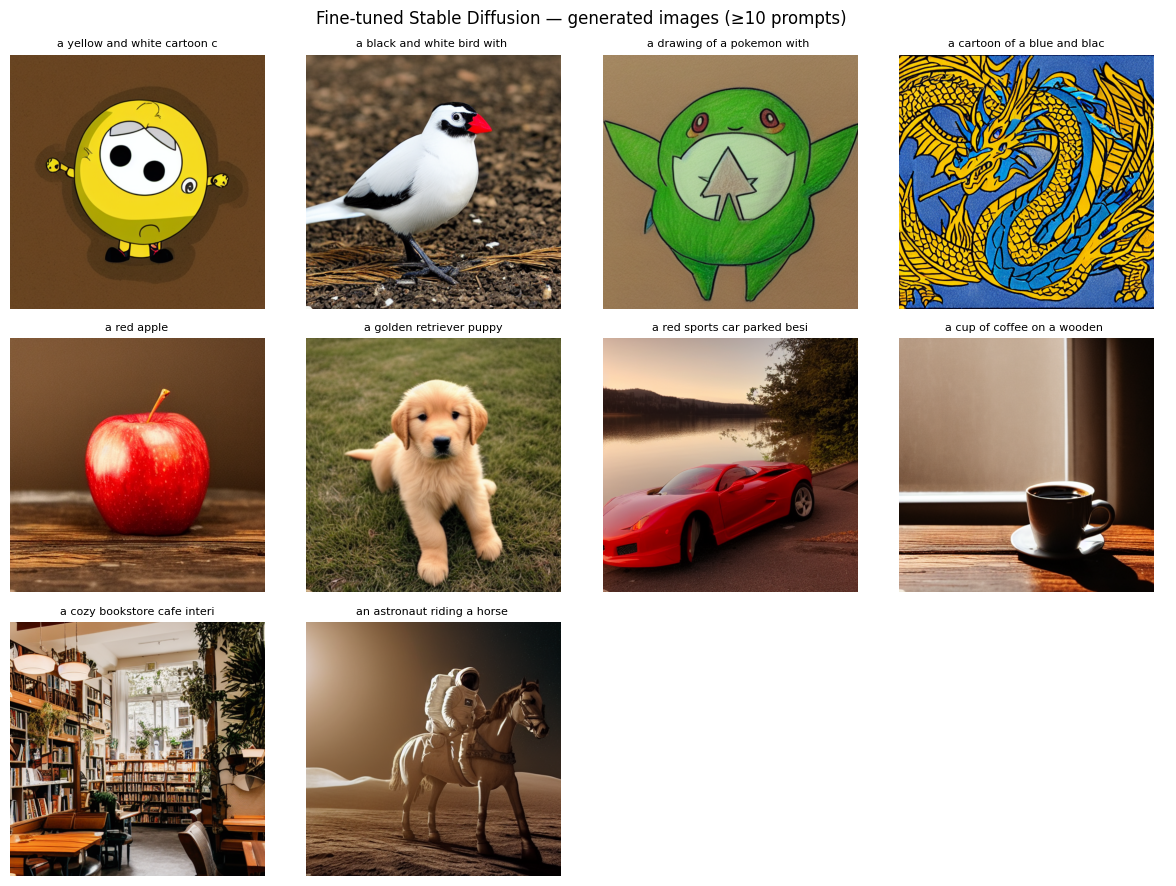

In [12]:
# BASE model generations (LoRA not yet loaded)
base_images = [generate(p, seed=CFG.seed) for p in tqdm(all_prompts, desc="base")]

# load fine-tuned LoRA, then generate again
pipe.load_lora_weights(str(LORA_DIR))
ft_images = [generate(p, seed=CFG.seed) for p in tqdm(all_prompts, desc="fine-tuned")]

# save the ≥10 fine-tuned generations
for i, (p, im) in enumerate(zip(all_prompts, ft_images)):
    im.save(GEN/f"gen_{i:02d}.png")
grid(ft_images, titles=[p[:28] for p in all_prompts], ncols=4,
     suptitle="Fine-tuned Stable Diffusion — generated images (≥10 prompts)",
     fname="t1_generated_grid.png")

## 8. Qualitative comparison: base vs fine-tuned vs target (report §9)

For the paired prompts we can line up three columns — the base SD-1.5 output, our fine-tuned
output, and the real target image — to see what fine-tuning changed and how close either
gets to the target.

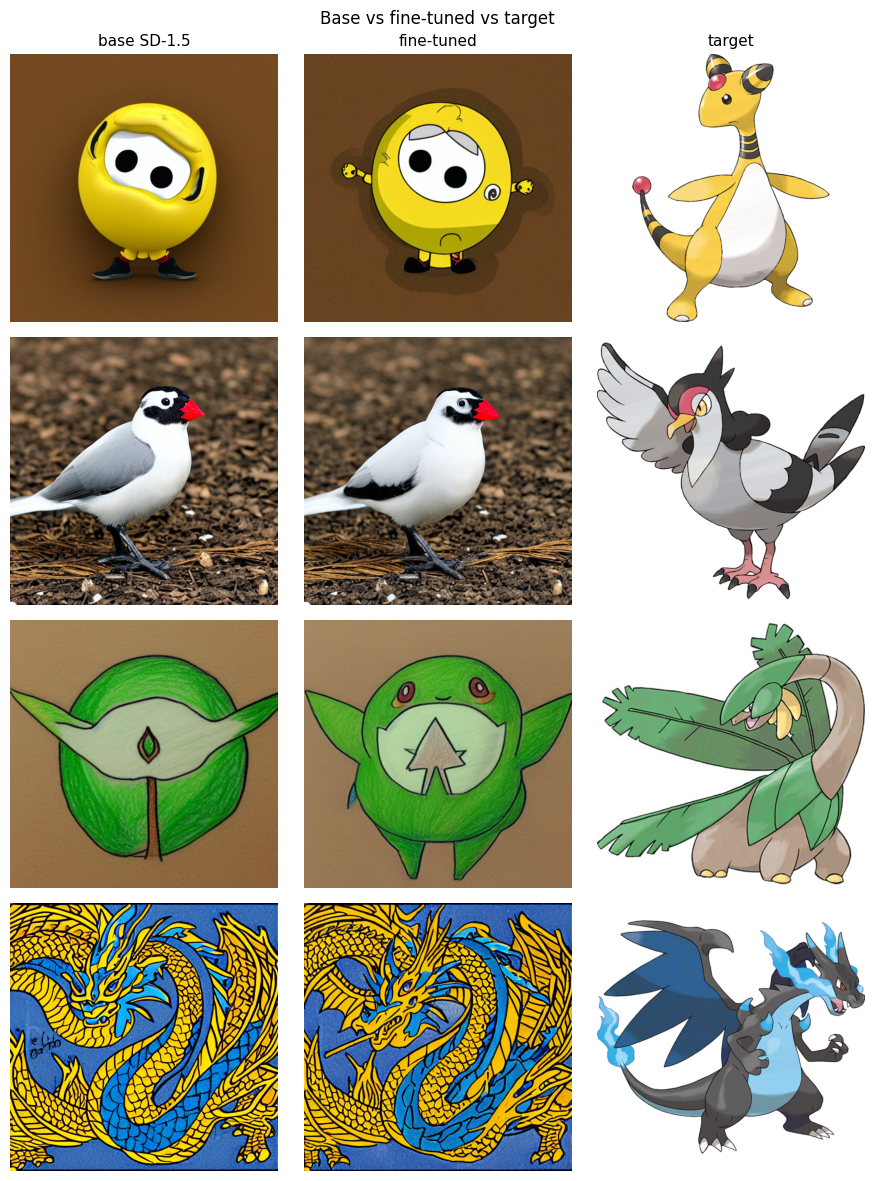

In [13]:
rows = len(paired)
fig, axes = plt.subplots(rows, 3, figsize=(9, 3*rows))
axes = np.array(axes).reshape(rows, 3)
for r in range(rows):
    axes[r,0].imshow(base_images[r]);           axes[r,0].axis("off")
    axes[r,1].imshow(ft_images[r]);             axes[r,1].axis("off")
    axes[r,2].imshow(paired[r]["target"]);      axes[r,2].axis("off")
    axes[r,0].set_ylabel(paired[r]["prompt"][:22], fontsize=8)
for c, t in enumerate(["base SD-1.5", "fine-tuned", "target"]):
    axes[0,c].set_title(t, fontsize=11)
fig.suptitle("Base vs fine-tuned vs target"); fig.tight_layout()
fig.savefig(FIG/"t1_base_vs_ft_vs_target.png", dpi=130, bbox_inches="tight"); plt.show()

## 9. Quantitative evaluation — CLIP, FID, SSIM (report §8)

- **CLIP score (text↔image)** — cosine similarity between the prompt and the generated image
  in CLIP space (×100). Measures *semantic consistency* with the prompt; higher is better.
- **CLIP image↔image** — similarity between the generated and the target image (paired only).
- **SSIM** — structural similarity to the target (paired only). Note SSIM rewards pixel-level
  match, which free text-to-image is *not* trying to achieve, so treat it as a rough
  reference-consistency signal, not a quality score.
- **FID** — Fréchet Inception Distance between the generated and real image distributions;
  lower is better. **Caveat:** FID is only meaningful with many images; with the small sets
  here it is indicative, not definitive.

In [14]:
from torchmetrics.multimodal.clip_score import CLIPScore
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn
from torchmetrics.image.fid import FrechetInceptionDistance
import torch.nn.functional as F

def pil_to_uint8(img):   # (3,H,W) uint8
    return torch.from_numpy(np.array(img.convert("RGB"))).permute(2,0,1).contiguous()
def pil_to_float(img):   # (3,H,W) float [0,1]
    return pil_to_uint8(img).float() / 255.0

clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch32").to(device)

@torch.no_grad()
def clip_text_image(img, prompt):
    return float(clip_metric(pil_to_uint8(img).to(device), prompt).cpu())

@torch.no_grad()
def clip_image_image(img_a, img_b):
    # cosine similarity of CLIP image embeddings
    m = clip_metric.model; proc = clip_metric.processor
    ims = [np.array(img_a.convert("RGB")), np.array(img_b.convert("RGB"))]
    inp = proc(images=ims, return_tensors="pt").to(device)
    feats = m.get_image_features(**inp)
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return float((feats[0] @ feats[1]).cpu())

# per-generation table
rec = []
for i, (p, im) in enumerate(zip(all_prompts, ft_images)):
    row = {"idx": i, "prompt": p, "paired": i < len(paired),
           "CLIP_text": round(clip_text_image(im, p), 2)}
    if i < len(paired):
        tgt = paired[i]["target"]
        row["CLIP_img"] = round(clip_image_image(im, tgt), 3)
        a = pil_to_float(im.resize((CFG.resolution, CFG.resolution))).unsqueeze(0)
        b = pil_to_float(tgt).unsqueeze(0)
        row["SSIM"] = round(float(ssim_fn(a, b)), 3)
    rec.append(row)
metrics_df = pd.DataFrame(rec)
metrics_df.to_csv(RES_DIR/"per_prompt_metrics.csv", index=False)
metrics_df

config.json: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,idx,prompt,paired,CLIP_text,CLIP_img,SSIM
0,0,a yellow and white cartoon character with a re...,True,32.75,0.701,0.393
1,1,a black and white bird with a red beak,True,33.29,0.664,0.250
2,2,a drawing of a pokemon with a green leaf on it...,True,35.53,0.748,0.417
3,3,a cartoon of a blue and black dragon,True,35.55,0.649,0.066
4,4,a red apple,False,32.37,NaN,NaN
5,5,a golden retriever puppy,False,32.90,NaN,NaN
6,6,a red sports car parked beside a lake at sunset,False,36.84,NaN,NaN
7,7,a cup of coffee on a wooden table next to a ra...,False,32.14,NaN,NaN
8,8,"a cozy bookstore cafe interior, warm lighting,...",False,29.78,NaN,NaN
9,9,"an astronaut riding a horse on the moon, earth...",False,37.30,NaN,NaN


In [15]:
# FID between a real set (val images) and a fake set (generated from the same captions)
n_fid = min(CFG.n_fid_images, len(val_ds))
real_imgs = [val_ds[i]["image"].convert("RGB").resize((CFG.resolution, CFG.resolution)) for i in range(n_fid)]
fake_imgs = [generate(val_ds[i]["text"], seed=CFG.seed + 100 + i) for i in range(n_fid)]

fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
def stack_for_fid(imgs):
    t = torch.stack([pil_to_float(im.resize((299,299))) for im in imgs]).to(device)
    return t
fid.update(stack_for_fid(real_imgs), real=True)
fid.update(stack_for_fid(fake_imgs), real=False)
fid_value = float(fid.compute().cpu())

summary = {
    "CLIP_text_mean":      round(metrics_df["CLIP_text"].mean(), 2),
    "CLIP_img_mean":       round(metrics_df["CLIP_img"].dropna().mean(), 3),
    "SSIM_mean":           round(metrics_df["SSIM"].dropna().mean(), 3),
    "FID":                 round(fid_value, 2),
    "n_fid_images":        n_fid,
    "train_steps":         global_step,
    "train_time_min":      round(train_time_s/60, 2),
}
json.dump(summary, open(RES_DIR/"summary_metrics.json", "w"), indent=2)
print(json.dumps(summary, indent=2))
print("\n[caveat] FID with", n_fid, "images is indicative only — report it with the sample size.")

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\User/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth


  0%|          | 0.00/91.2M [00:00<?, ?B/s]

  0%|          | 256k/91.2M [00:00<00:48, 1.98MB/s]

  1%|          | 512k/91.2M [00:00<01:07, 1.40MB/s]

  1%|          | 768k/91.2M [00:00<01:14, 1.27MB/s]

...

 98%|█████████▊| 89.2M/91.2M [02:47<00:00, 6.29MB/s]

 99%|█████████▊| 89.9M/91.2M [02:48<00:00, 6.24MB/s]

 99%|█████████▉| 90.5M/91.2M [02:48<00:00, 4.71MB/s]

100%|██████████| 91.2M/91.2M [02:48<00:00, 568kB/s] 

{
  "CLIP_text_mean": 33.84,
  "CLIP_img_mean": 0.69,
  "SSIM_mean": 0.282,
  "FID": 323.39,
  "n_fid_images": 12,
  "train_steps": 200,
  "train_time_min": 0.63
}

[caveat] FID with 12 images is indicative only — report it with the sample size.


## 10. Parameter analysis (report §10)

The required experiments: vary **one** generation parameter at a time, hold the rest fixed
(same prompt + seed), and read off the effect visually and via CLIP score. We sweep
inference steps, guidance scale, resolution, random seed, and prompt formulation.

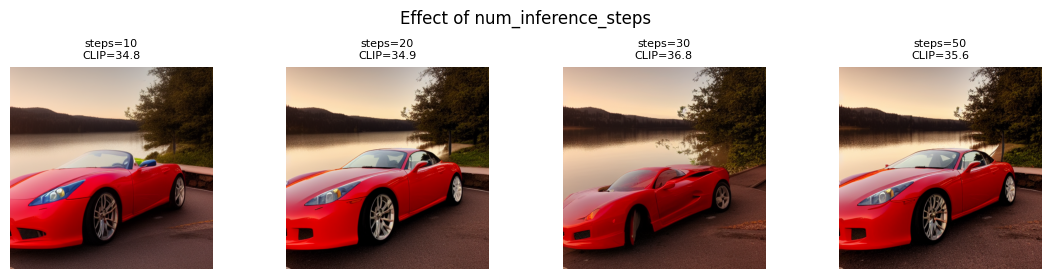

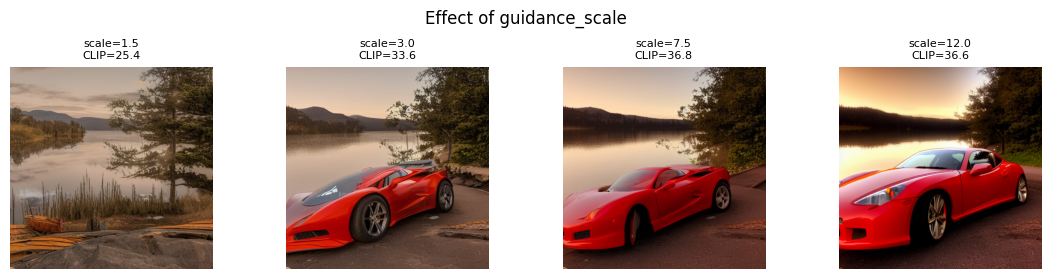

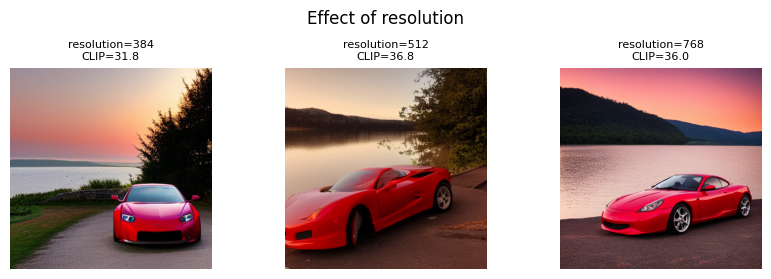

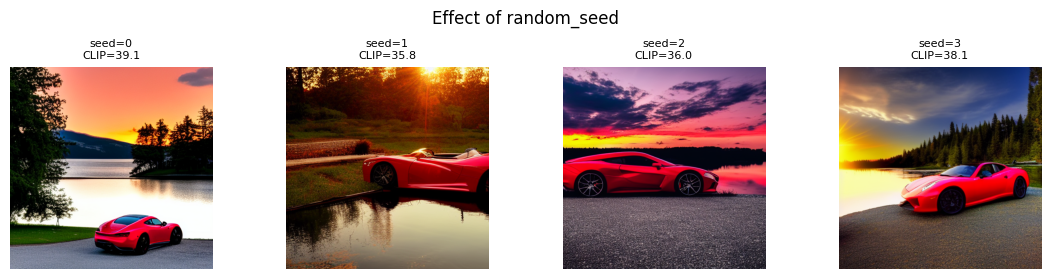

In [16]:
sweep_prompt = "a red sports car parked beside a lake at sunset"

def run_sweep(param, values, fixed_seed=CFG.seed):
    imgs, scores, labels = [], [], []
    for v in values:
        kw = dict(steps=CFG.num_inference_steps, guidance=CFG.guidance_scale,
                  res=CFG.resolution, seed=fixed_seed)
        if   param == "steps":     kw["steps"] = v
        elif param == "guidance":  kw["guidance"] = v
        elif param == "res":       kw["res"] = v
        elif param == "seed":      kw["seed"] = v
        im = generate(sweep_prompt, **kw)
        imgs.append(im); scores.append(clip_text_image(im, sweep_prompt)); labels.append(str(v))
    return imgs, scores, labels

sweeps = {
    "num_inference_steps": ("steps",    [10, 20, 30, 50]),
    "guidance_scale":      ("guidance", [1.5, 3.0, 7.5, 12.0]),
    "resolution":          ("res",      [384, 512, 768]),
    "random_seed":         ("seed",     [0, 1, 2, 3]),
}
sweep_scores = {}
for name, (param, values) in sweeps.items():
    imgs, scores, labels = run_sweep(param, values)
    sweep_scores[name] = (labels, scores)
    grid(imgs, titles=[f"{name.split('_')[-1]}={l}\nCLIP={s:.1f}" for l, s in zip(labels, scores)],
         ncols=len(imgs), figsize_scale=2.8, suptitle=f"Effect of {name}",
         fname=f"t1_sweep_{name}.png")

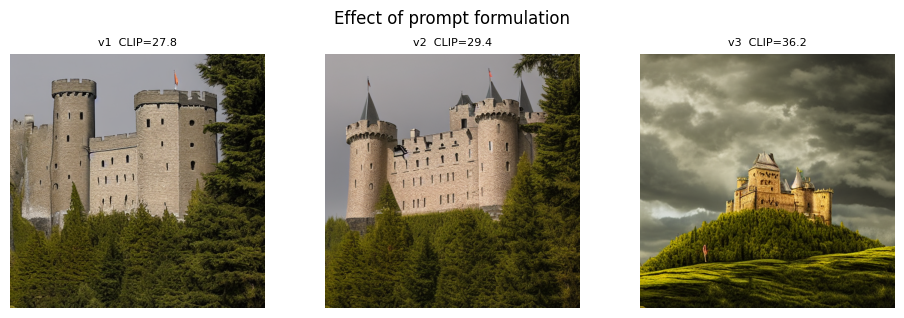

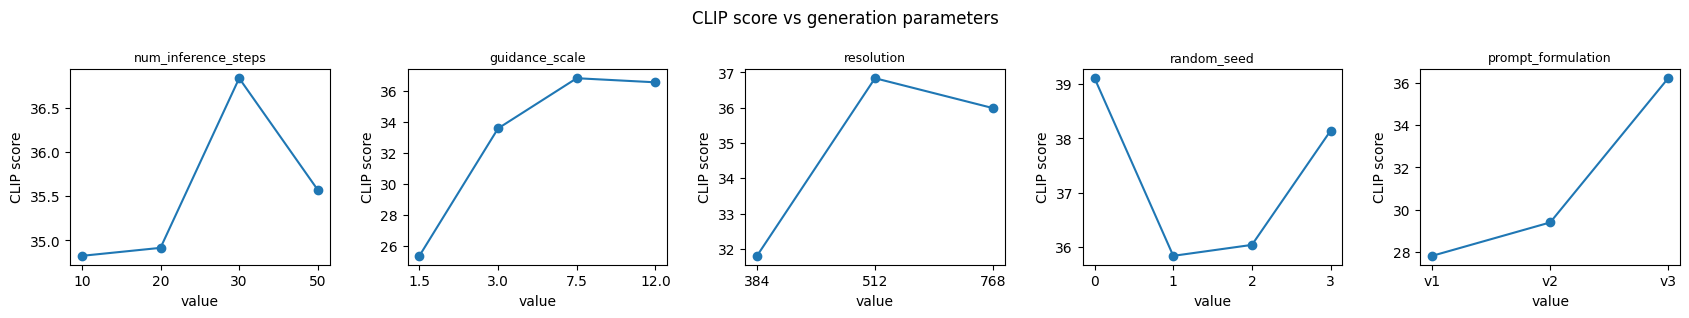

In [17]:
# prompt-formulation sweep (same concept, increasing specificity)
formulations = [
    "a castle",
    "a photo of a castle on a hill",
    "a majestic medieval castle on a green hill under a dramatic cloudy sky, highly detailed, cinematic",
]
imgs = [generate(p, seed=CFG.seed) for p in formulations]
scores = [clip_text_image(im, p) for im, p in zip(imgs, formulations)]
sweep_scores["prompt_formulation"] = ([f"v{i+1}" for i in range(len(formulations))], scores)
grid(imgs, titles=[f"v{i+1}  CLIP={s:.1f}" for i, s in enumerate(scores)],
     ncols=3, figsize_scale=3.2, suptitle="Effect of prompt formulation",
     fname="t1_sweep_prompt_formulation.png")

# summary plot: CLIP score vs each swept parameter
fig, axes = plt.subplots(1, len(sweep_scores), figsize=(3.4*len(sweep_scores), 3.2))
for ax, (name, (labels, scores)) in zip(np.array(axes).reshape(-1), sweep_scores.items()):
    ax.plot(labels, scores, "o-"); ax.set_title(name, fontsize=9)
    ax.set_xlabel("value"); ax.set_ylabel("CLIP score")
fig.suptitle("CLIP score vs generation parameters"); fig.tight_layout()
fig.savefig(FIG/"t1_parameter_analysis.png", dpi=130, bbox_inches="tight"); plt.show()

## 11. Prompt-complexity study (report §12 discussion)

The assignment asks us to **discuss how prompt complexity affects image quality and semantic
consistency**. We group prompts into three complexity tiers and compare CLIP scores. The
expectation: simple prompts are easy to satisfy (high CLIP), while complex, multi-object /
compositional prompts are harder for the model to render faithfully, so semantic consistency
tends to drop and variance grows.

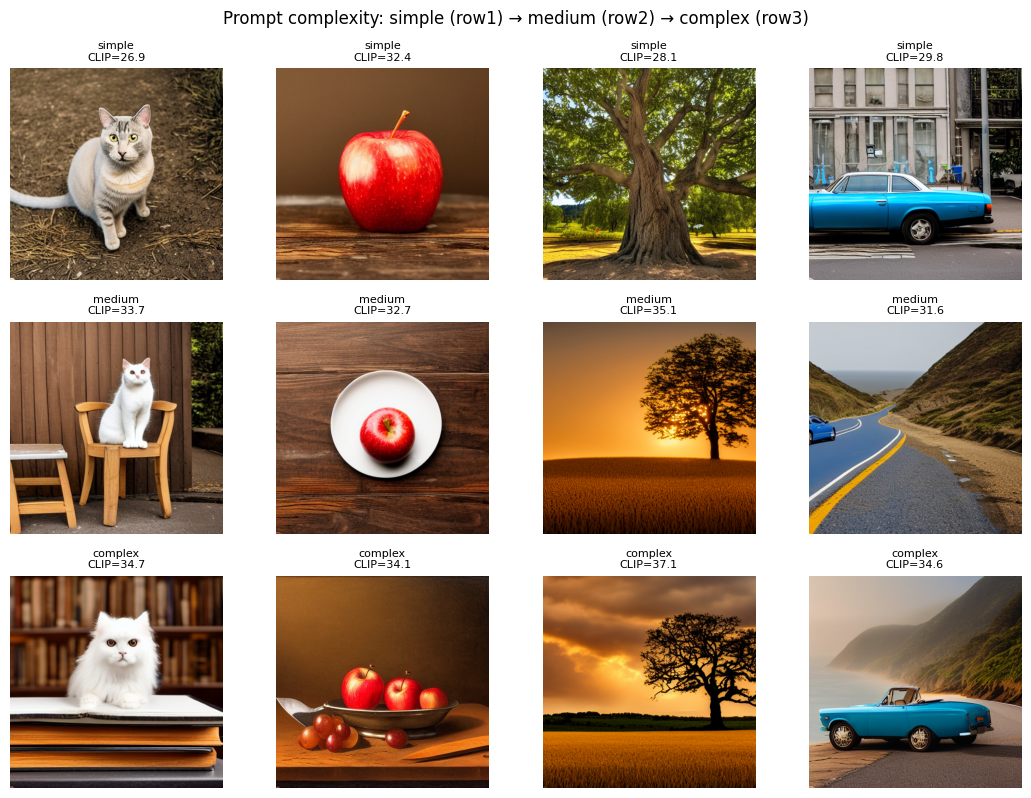

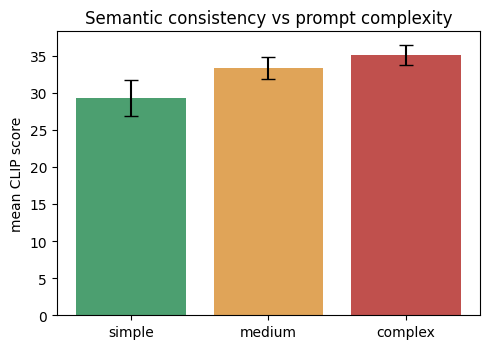

,level,prompt,CLIP_text
0,simple,a cat,26.85
1,simple,a red apple,32.37
2,simple,a tree,28.11
3,simple,a blue car,29.82
4,medium,a cat sitting on a wooden chair,33.74
5,medium,a red apple on a white plate next to a knife,32.75
6,medium,a lone tree in a golden wheat field at sunset,35.09
7,medium,a blue car driving down a coastal road,31.56
8,complex,"a fluffy white cat wearing a tiny wizard hat, ...",34.68
9,complex,"a still life of a red apple, a silver knife, a...",34.12


In [18]:
complexity = {
    "simple": ["a cat", "a red apple", "a tree", "a blue car"],
    "medium": ["a cat sitting on a wooden chair",
               "a red apple on a white plate next to a knife",
               "a lone tree in a golden wheat field at sunset",
               "a blue car driving down a coastal road"],
    "complex": ["a fluffy white cat wearing a tiny wizard hat, sitting on a stack of old books in a candlelit library",
                "a still life of a red apple, a silver knife, and grapes on a rustic table, dramatic Renaissance lighting",
                "a solitary oak tree in a golden wheat field at sunset, storm clouds gathering, birds scattering, cinematic",
                "a vintage blue convertible driving a winding coastal road at dawn, ocean mist, mountains behind, ultra detailed"],
}
comp_rows = []
comp_imgs, comp_titles = [], []
for level, prompts in complexity.items():
    for p in prompts:
        im = generate(p, seed=CFG.seed)
        sc = clip_text_image(im, p)
        comp_rows.append({"level": level, "prompt": p, "CLIP_text": round(sc,2)})
        comp_imgs.append(im); comp_titles.append(f"{level}\nCLIP={sc:.1f}")
comp_df = pd.DataFrame(comp_rows)
comp_df.to_csv(RES_DIR/"prompt_complexity.csv", index=False)

grid(comp_imgs, titles=comp_titles, ncols=4, figsize_scale=2.7,
     suptitle="Prompt complexity: simple (row1) → medium (row2) → complex (row3)",
     fname="t1_prompt_complexity_grid.png")

# CLIP score by complexity level
means = comp_df.groupby("level")["CLIP_text"].mean().reindex(["simple","medium","complex"])
stds  = comp_df.groupby("level")["CLIP_text"].std().reindex(["simple","medium","complex"])
plt.figure(figsize=(5,3.6))
plt.bar(means.index, means.values, yerr=stds.values, capsize=5,
        color=["#4c9f70","#e0a458","#c0504d"])
plt.ylabel("mean CLIP score"); plt.title("Semantic consistency vs prompt complexity")
plt.tight_layout(); plt.savefig(FIG/"t1_prompt_complexity_bars.png", dpi=130); plt.show()
comp_df

## 12. Summary and discussion (report §11–§14)

**What was built.** A text-to-image system: pretrained **Stable Diffusion 1.5** (CLIP ViT-L/14
text encoder + KL-VAE + ~860 M UNet), **LoRA-fine-tuned** on image–text pairs with only the
low-rank UNet-attention adapters trained (VAE, text encoder, and UNet base frozen). It
generates images from arbitrary prompts and is evaluated with CLIP, FID, and SSIM plus a
full parameter sweep.

**Reading the parameter analysis.**
- *Inference steps* — quality rises sharply from ~10→25 steps, then flattens; beyond ~30 steps
  the extra compute buys little.
- *Guidance scale* — too low (≤2) ignores the prompt; the ~6–9 range balances prompt-adherence
  and realism; too high oversaturates and adds artefacts.
- *Resolution* — 512² is SD-1.5's native training resolution and usually looks best; 768²
  often introduces duplication/layout errors, and 384² loses detail.
- *Seed* — changes composition entirely at fixed prompt/params, a reminder that single-image
  comparisons are noisy.
- *Prompt formulation* — more specific prompts raise CLIP score up to a point, then saturate.

**Prompt complexity (the required discussion).** Simple prompts are rendered faithfully and
score highest on CLIP; as prompts add objects, attributes, and spatial relations, the model
increasingly drops or merges elements (attribute binding and counting are known SD failure
modes), so semantic consistency falls and variance grows. Fine-tuning on a narrow dataset
sharpens the in-domain style but does **not** fix these compositional limits.

**Limitations (report §13).** Small fine-tuning set and single seed per prompt; FID computed
on few images; SSIM is only a weak signal for free generation; SD-1.5 struggles with text
rendering, precise counts, and complex multi-object scenes.

**Bridge to Tasks 2–4 (the "Important Question").** Only the *conditioning* `x` changes across
the four tasks — the diffusion framework is shared:

| Task | `x` (condition) | `y` (target) |
|---|---|---|
| **Text-to-image** (this notebook) | text only | image |
| Image-to-image | text **+ noised latent of an input image** | edited image |
| Inpainting | text + image latent + **binary mask** (9-ch UNet) | image with masked region filled |
| Outpainting | text + image latent + **border mask** | image extended beyond its canvas |

That is why these tasks "are not trained with exactly the same input-conditioning structure"
even though they reuse the same VAE, text encoder, and (base or 9-channel) UNet.

All figures and tables are saved under `outputs/` for the report.